# Lecture 2 — Model Answer
## Bar Charts: World Happiness Report 2023



---


In [1]:
import pandas as pd
import numpy as np
import plotly.express as px

# Dataset: World Happiness Report 2023
# Real dataset: https://www.kaggle.com/datasets/ajaypalsinghlo/world-happiness-report-2023
# Place the downloaded CSV at: data/world_happiness_2023.csv
df = pd.read_csv('../data/world_happiness_2023.csv')

# Rename columns for convenience
df.columns = ['Country','Region','Happiness_Score','GDP','Social_Support',
              'Life_Expectancy','Freedom','Generosity','Corruption']
print(f"{len(df)} countries loaded")
print(df.head())


63 countries loaded
       Country                        Region  Happiness_Score     GDP  \
0      Finland                Western Europe            7.804  10.775   
1      Denmark                Western Europe            7.586  10.933   
2      Iceland                Western Europe            7.525  10.878   
3       Israel  Middle East and North Africa            7.473  10.527   
4  Netherlands                Western Europe            7.464  11.015   

   Social_Support  Life_Expectancy  Freedom  Generosity  Corruption  
0           0.954             71.9    0.949       0.142       0.179  
1           0.954             72.7    0.931       0.168       0.234  
2           0.983             72.5    0.961       0.260       0.150  
3           0.916             72.4    0.903       0.149       0.826  
4           0.939             72.4    0.879       0.240       0.296  


---
## Task 1 — Regional Comparison Bar Chart

**Story:** Western Europe sits in a league of its own — more than 1.5 points above the nearest region. Sub-Saharan Africa and South Asia trail by over 2.5 points.


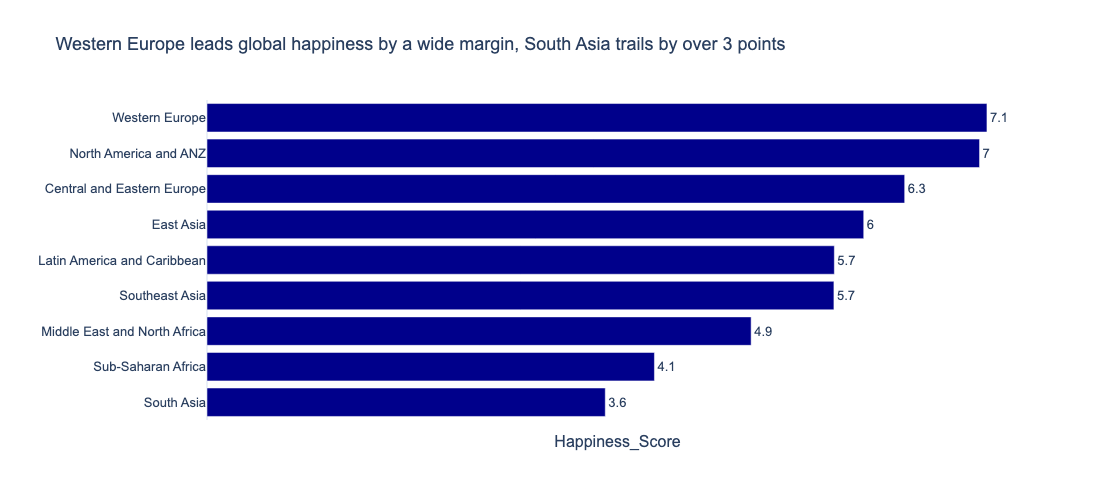

In [2]:

# prep data
region_avg = df.groupby('Region')['Happiness_Score'].mean().reset_index().sort_values('Happiness_Score')

# create a plotly express
fig = px.bar(
    data_frame=region_avg,
    x='Happiness_Score', 
    y='Region', orientation='h',
    text=region_avg['Happiness_Score'].round(1), # text over or inside the bars
    title='Western Europe leads global happiness by a wide margin, South Asia trails by over 3 points',
    labels={'Happiness Score': 'Happiness Score (1 - 10)', 'Region': ''},
    template='plotly_white',
    color_discrete_sequence=['darkblue']
)

# add needed customizations

fig.update_traces(
    textposition='outside', # controls where the text on the bars is positioned
)

fig.update_layout(
    xaxis=dict(showgrid=False, showticklabels=False),
    font=dict(family='Arial', size=13),
    height=500
)

fig.show()

---
## Task 2 — Bottom vs. Top: A Contrast Story


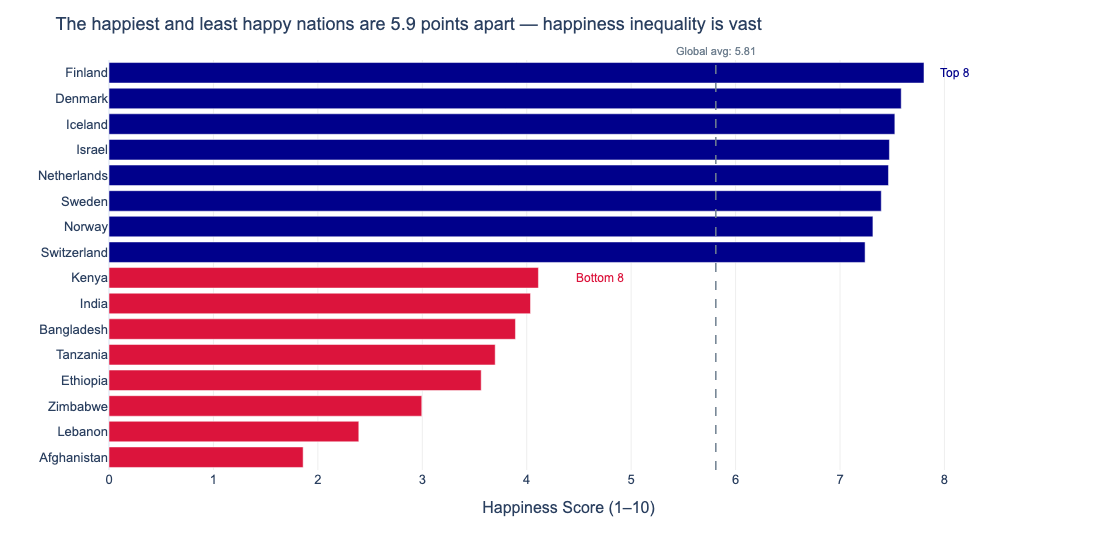

In [3]:
# prep data
top8 = df.nlargest(8,'Happiness_Score').assign(Group='Top 8')
bottom8 = df.nsmallest(8,'Happiness_Score').assign(Group='Bottom 8')
combined = pd.concat([bottom8, top8]).sort_values('Happiness_Score').reset_index(drop=True)
global_avg = df['Happiness_Score'].mean()

# set colors for the top and bottom groups
colors = ['darkblue' if g == 'Top 8' else 'crimson' for g in combined['Group']]



fig = px.bar(
    data_frame=combined,
    x='Happiness_Score', y='Country',
    orientation='h',
    color='Group',
    color_discrete_map={'Top 8': 'darkblue', 'Bottom 8': 'crimson'},
    hover_data={'Region': True, 'Happiness_Score': ':.2f', 'Group': False, 'Happiness_Score': True},
    template='plotly_white'
)


# adding the average vertical line
fig.add_vline(x=global_avg, 
              line_dash='dash', line_color='slategrey', line_width=1.5,
              annotation_text=f'Global avg: {global_avg:.2f}',
              annotation_position='top', 
              annotation_font=dict(size=11, color='slategrey'))


# adding the text highlighting the gap, top and bottom numbers- global average reference line gives a meaningful anchor 


gap = top8['Happiness_Score'].max() - bottom8['Happiness_Score'].min()

fig.add_annotation(x=8.1, y=15, 
                   text='Top 8',
                   showarrow=False, 
                   font=dict(color='darkblue', size=12))

fig.add_annotation(x=4.7, y=7, 
                   text='Bottom 8',
                   showarrow=False, 
                   font=dict(color='crimson', size=12))

fig.update_layout(
    title=f'The happiest and least happy nations are {gap:.1f} points apart — happiness inequality is vast',
    xaxis=dict(range=[0, 8.8], gridcolor='#EEEEEE', title='Happiness Score (1–10)'),
    yaxis=dict(title=''),
    font=dict(family='Arial', size=13),
    showlegend=False,
    height=550
)
fig.show()
